<div style="text-align: center; font-style: italic; font-size: 18px">Water Resources Management</div>
<div></div>
<div style="text-align: center">Supplementary Information of</div>
<div style="text-align: center; font-weight: bold; font-size: 24px">Data-Driven Leak Localization Modeling for Optimal Sensor Placement</div>

---

Maria Gloria Di Chiano<sup>1*</sup>, Dennis Zanutto<sup>2,3</sup>, Gianfranco Becciu<sup>1</sup>, Dragan Savić<sup>3,4</sup>

<sup>1</sup>D.I.C.A. Politecnico di Milano, 20133 Milano, Italy

<sup>2</sup>D.E.I.B, Politecnico di Milano, 20133, Milano, Italy

<sup>3</sup>KWR Water Research Institute, Nieuwegein, 3430 BB, the Netherlands

<sup>4</sup>Centre for Water Systems, University of Exeter, Exeter, EX4 4QF, United Kingdom


## Content of this File

- Text S2.1
- Text S2.2

## Introduction

This notebook tests whether we can improve the leak signature matrix (LSM) reconstruction method proposed by Boatwright et al..

In [1]:
# Imports
from wdn_osp_ll.sensor_placement_optimization import load_or_compute
from wdn_osp_ll.visualization import (
    plot_pareto_front_nsensors_msa,
    plot_hypervolume_bar,
    plot_hypervolume_trajectory,
)

## Text S2

### S2.1 — Alternative Algorithmic Configurations

The goal of this comparison is to test two different implementations of the algorithm proposed by Boatwright et al.:

1. sources can also be considered as sensors for the interpolation, in that case they would always record a pressure drop of 0 meters;
2. the distances between sensors are computed using a directed graph.

In [2]:
suggested_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "boatwright",
                    "args": {
                        "metric": "length",
                        "directed": False,
                        "exponent": None,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

suggested_res = load_or_compute(config=suggested_cfg)

In [3]:
usesources_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "boatwright",
                    "args": {
                        "metric": "length",
                        "directed": False,
                        "exponent": None,
                        "sources_as_sensors": True,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                        
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

usesources_res = load_or_compute(config=usesources_cfg)

Starting optimisation...
[2026-11-06 12:13:08] generation      0 | best hypervolume: 183.645161 | median: 157.193548
[2026-11-06 12:13:10] generation     10 | best hypervolume: 317.129032 | median: 299.709677
[2026-11-06 12:13:11] generation     20 | best hypervolume: 326.193548 | median: 319.935484
[2026-11-06 12:13:11] generation     30 | best hypervolume: 328.064516 | median: 323.145161
[2026-11-06 12:13:11] generation     40 | best hypervolume: 329.064516 | median: 327.000000
[2026-11-06 12:13:12] generation     50 | best hypervolume: 330.225806 | median: 327.451613
[2026-11-06 12:13:12] generation     60 | best hypervolume: 330.387097 | median: 328.225806
[2026-11-06 12:13:13] generation     70 | best hypervolume: 330.419355 | median: 328.564516
[2026-11-06 12:13:13] generation     80 | best hypervolume: 330.548387 | median: 329.112903
[2026-11-06 12:13:13] generation     90 | best hypervolume: 330.709677 | median: 329.500000
[2026-11-06 12:13:14] generation    100 | best hypervol

In [5]:
directed_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "boatwright",
                    "args": {
                        "metric": "length",
                        "directed": True,
                        "exponent": None,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

directed_res = load_or_compute(config=directed_cfg, force_recompute=True)

Starting optimisation...
[2026-11-06 12:13:28] generation      0 | best hypervolume: 193.419355 | median: 143.258065
[2026-11-06 12:13:29] generation     10 | best hypervolume: 325.000000 | median: 312.129032
[2026-11-06 12:13:29] generation     20 | best hypervolume: 334.000000 | median: 330.564516
[2026-11-06 12:13:30] generation     30 | best hypervolume: 336.709677 | median: 333.709677
[2026-11-06 12:13:30] generation     40 | best hypervolume: 338.935484 | median: 335.112903
[2026-11-06 12:13:31] generation     50 | best hypervolume: 339.612903 | median: 336.629032
[2026-11-06 12:13:31] generation     60 | best hypervolume: 339.741935 | median: 337.677419
[2026-11-06 12:13:32] generation     70 | best hypervolume: 339.838710 | median: 338.274194
[2026-11-06 12:13:32] generation     80 | best hypervolume: 340.161290 | median: 338.951613
[2026-11-06 12:13:32] generation     90 | best hypervolume: 340.161290 | median: 339.209677
[2026-11-06 12:13:33] generation    100 | best hypervol

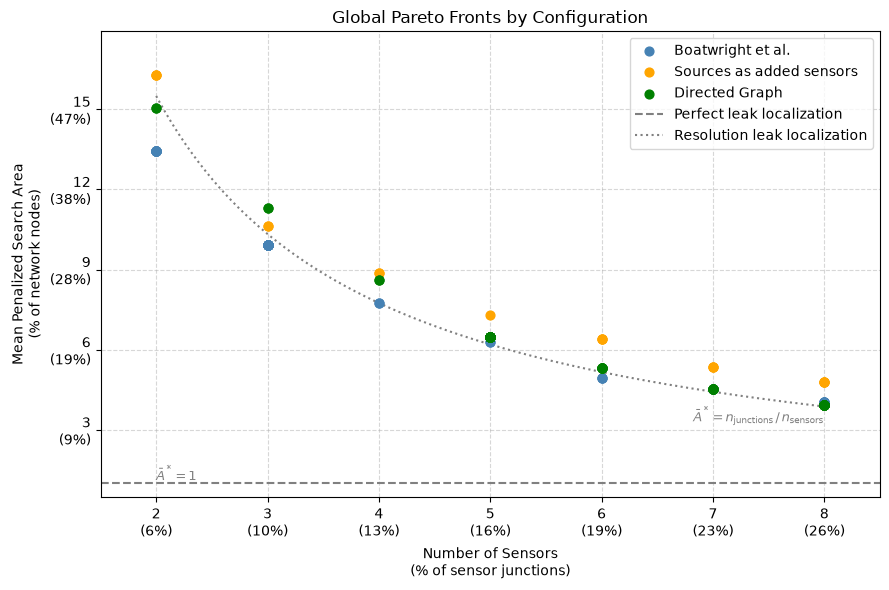

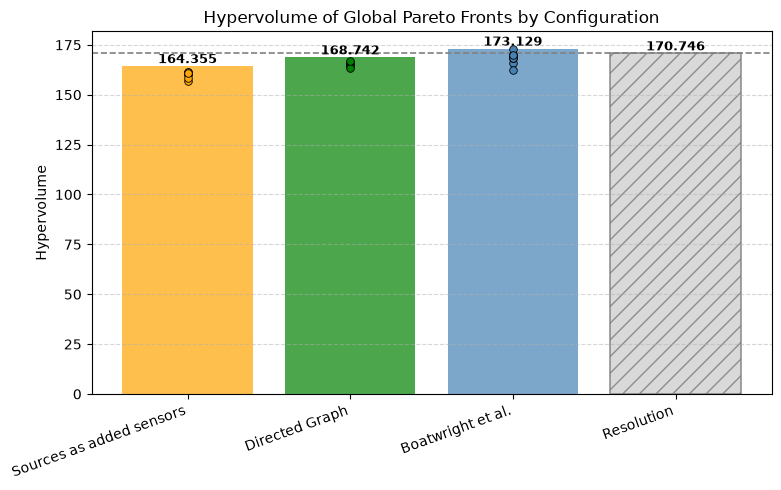

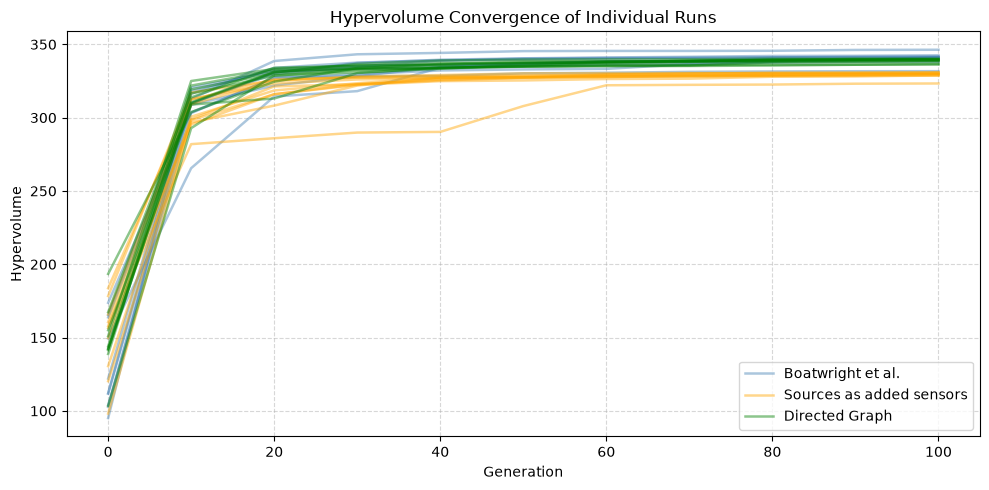

In [6]:
results = [suggested_res, usesources_res, directed_res]
labels = ["Boatwright et al.", "Sources as added sensors", "Directed Graph"]
colors = ["steelblue", "orange", "green"]

fig, ax = plot_pareto_front_nsensors_msa(results, labels, colors)
fig, ax = plot_hypervolume_bar(results, labels, colors)
fig, ax = plot_hypervolume_trajectory(results, labels, colors)

**Results.** The default configuration, i.e., undirected graph to calculate the distance between sensors and sources are ignored from the reconstruction, works better than both alternatives.
We will proceed with that configuration.

### S2.2 — Alternative Distance Metric

The goal of this comparison is to test wheter a distance metric based on the pipe's resistance factor instead of its length works best.
We test it in using both the directed and undirected graph.

In [7]:
resistance_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "boatwright",
                    "args": {
                        "metric": "resistance",
                        "directed": False,
                        "exponent": None,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

resistance_res = load_or_compute(config=resistance_cfg)

Starting optimisation...
[2026-11-06 12:16:06] generation      0 | best hypervolume: 142.387097 | median: 108.145161
[2026-11-06 12:16:07] generation     10 | best hypervolume: 281.096774 | median: 257.774194
[2026-11-06 12:16:07] generation     20 | best hypervolume: 290.967742 | median: 284.000000
[2026-11-06 12:16:07] generation     30 | best hypervolume: 292.741935 | median: 290.354839
[2026-11-06 12:16:08] generation     40 | best hypervolume: 296.677419 | median: 291.887097
[2026-11-06 12:16:08] generation     50 | best hypervolume: 296.903226 | median: 292.693548
[2026-11-06 12:16:09] generation     60 | best hypervolume: 297.258065 | median: 294.370968
[2026-11-06 12:16:09] generation     70 | best hypervolume: 297.516129 | median: 294.935484
[2026-11-06 12:16:09] generation     80 | best hypervolume: 297.838710 | median: 295.241935
[2026-11-06 12:16:10] generation     90 | best hypervolume: 300.677419 | median: 295.435484
[2026-11-06 12:16:10] generation    100 | best hypervol

In [8]:
resistance_directed_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "boatwright",
                    "args": {
                        "metric": "resistance",
                        "directed": True,
                        "exponent": None,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

resistance_directed_res = load_or_compute(config=resistance_directed_cfg)

Starting optimisation...
[2026-11-06 12:16:11] generation      0 | best hypervolume: 160.451613 | median: 129.951613
[2026-11-06 12:16:11] generation     10 | best hypervolume: 282.774194 | median: 267.274194
[2026-11-06 12:16:11] generation     20 | best hypervolume: 303.774194 | median: 291.370968
[2026-11-06 12:16:12] generation     30 | best hypervolume: 311.322581 | median: 305.032258
[2026-11-06 12:16:12] generation     40 | best hypervolume: 314.580645 | median: 306.322581
[2026-11-06 12:16:13] generation     50 | best hypervolume: 315.225806 | median: 307.161290
[2026-11-06 12:16:13] generation     60 | best hypervolume: 316.064516 | median: 308.806452
[2026-11-06 12:16:14] generation     70 | best hypervolume: 316.258065 | median: 309.532258
[2026-11-06 12:16:14] generation     80 | best hypervolume: 316.322581 | median: 311.016129
[2026-11-06 12:16:15] generation     90 | best hypervolume: 316.354839 | median: 311.354839
[2026-11-06 12:16:15] generation    100 | best hypervol

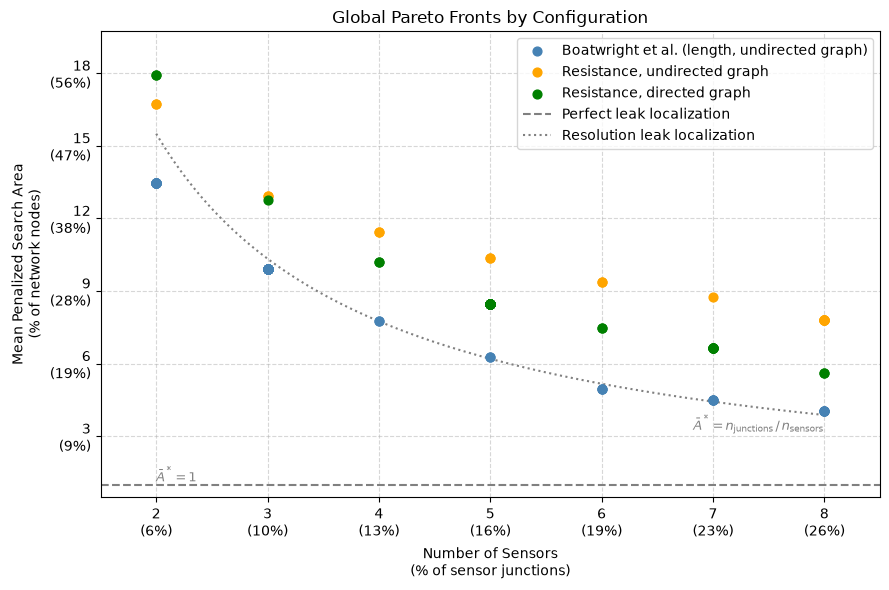

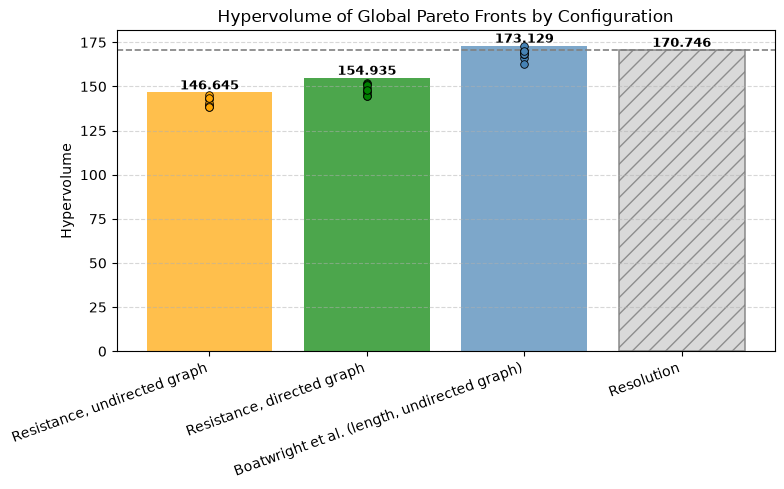

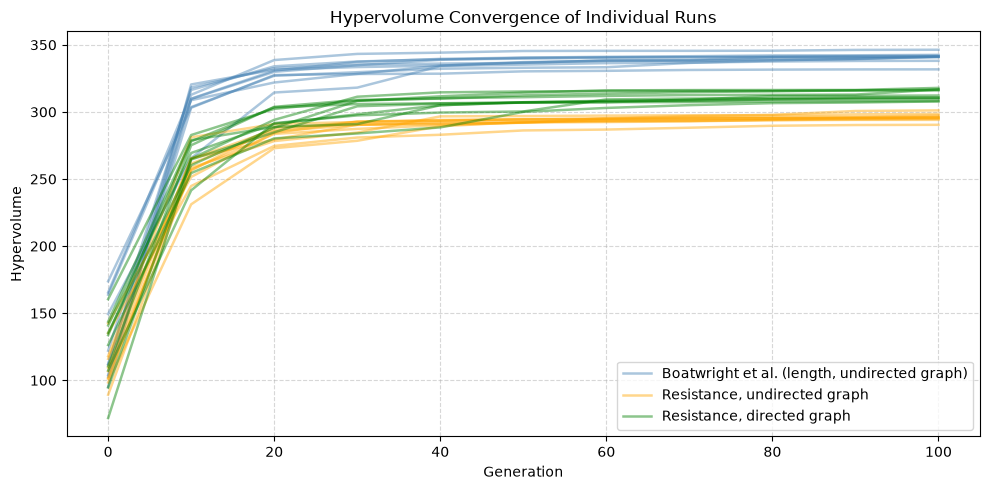

In [9]:
results = [suggested_res, resistance_res, resistance_directed_res]
labels = ["Boatwright et al. (length, undirected graph)", "Resistance, undirected graph", "Resistance, directed graph"]
colors = ["steelblue", "orange", "green", "purple"]

fig, ax = plot_pareto_front_nsensors_msa(results, labels, colors)
fig, ax = plot_hypervolume_bar(results, labels, colors)
fig, ax = plot_hypervolume_trajectory(results, labels, colors)

**Results.** Calculating the distance between nodes using the pipe lengths on an undirected graph of the network works best.
The resistance metric doesn't provide additional value.